In [29]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from llm.model import llm_model
from langgraph.checkpoint.memory import MemorySaver

In [30]:
model = llm_model()

In [31]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict):

    messages: Annotated[list[BaseMessage], add_messages]

In [32]:
def chat_node(state: ChatState):

    # take user query from state
    messages = state['messages']

    # send to llm 
    response = model.invoke(messages)

    # response store state
    return {'messages': [response]}

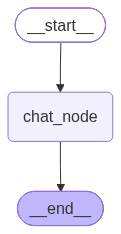

In [33]:
checkpointer = MemorySaver()

graph = StateGraph(ChatState)

# add nodes 
graph.add_node('chat_node', chat_node)

# edges 
graph.add_edge(START, 'chat_node')
graph.add_edge('chat_node', END)

chatbot = graph.compile(checkpointer=checkpointer)

chatbot

In [35]:
initial_state = {
    'messages': [HumanMessage(content='What is the capital of USA ?')]
}

result = chatbot.invoke(initial_state)

result

ValueError: Checkpointer requires one or more of the following 'configurable' keys: thread_id, checkpoint_ns, checkpoint_id

In [36]:
thread_id = '1'

while True:

    user_message = input('Type here: ')

    print(user_message)

    if user_message.strip().lower() in ['quit', 'bye']:
        break

    config = {'configurable': {'thread_id': thread_id}}

    response = chatbot.invoke({'messages': [HumanMessage(content=user_message)]}, config=config)

    print('AI:', response['messages'][-1].content)

hi
AI: Hello! How can I help you today?
quit


In [28]:
chatbot.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='hi', additional_kwargs={}, response_metadata={}, id='9c07cea9-45f3-42ce-8f53-abcd9f7b2ccb'), AIMessage(content='Hello! How can I assist you today?', additional_kwargs={}, response_metadata={'model': 'qwen2.5:1.5b', 'created_at': '2026-11-26T12:15:53.3450794Z', 'done': True, 'done_reason': 'stop', 'total_duration': 17094039000, 'load_duration': 16610845200, 'prompt_eval_count': 30, 'prompt_eval_duration': 138217000, 'eval_count': 10, 'eval_duration': 194341000, 'logprobs': None, 'model_name': 'qwen2.5:1.5b', 'model_provider': 'ollama'}, id='lc_run--01a217c8-5ac9-76a9-9b7b-9578d6eabbaf-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 30, 'output_tokens': 10, 'total_tokens': 40}), HumanMessage(content='my name is shishir', additional_kwargs={}, response_metadata={}, id='f9cb63b1-0456-4b7b-8d60-e2bcc264bf68'), AIMessage(content="Hello Shishir! It's nice to meet you. Is there anything specific you would like t